# Day 96 — Types of Neural Networks | History | Applications

In this notebook (NumPy, scikit-learn and Matplotlib only) we will:
1. Plot a **timeline of deep learning history**
2. See the core operation of each network type from scratch:
   - **MLP** forward pass
   - **CNN** convolution and pooling
   - **RNN** hidden state over a sequence
   - **Transformer** self-attention
   - **Autoencoder** reconstruction and anomaly detection
3. Build an **architecture chooser** for different applications

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import MinMaxScaler

np.random.seed(42)

## 1. History of Deep Learning: timeline

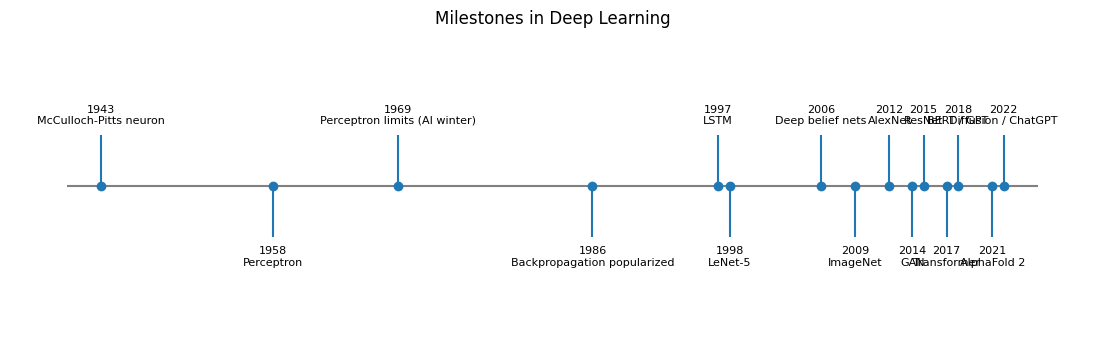

In [3]:
events = [
    (1943, "McCulloch-Pitts neuron"),
    (1958, "Perceptron"),
    (1969, "Perceptron limits (AI winter)"),
    (1986, "Backpropagation popularized"),
    (1997, "LSTM"),
    (1998, "LeNet-5"),
    (2006, "Deep belief nets"),
    (2009, "ImageNet"),
    (2012, "AlexNet"),
    (2014, "GAN"),
    (2015, "ResNet"),
    (2017, "Transformer"),
    (2018, "BERT / GPT"),
    (2021, "AlphaFold 2"),
    (2022, "Diffusion / ChatGPT"),
]

years = [e[0] for e in events]
fig, ax = plt.subplots(figsize=(14, 4))
ax.hlines(0, 1940, 2025, color="gray")
for i, (year, name) in enumerate(events):
    level = 1 if i % 2 == 0 else -1
    ax.vlines(year, 0, level * 0.6, color="tab:blue")
    ax.plot(year, 0, "o", color="tab:blue")
    ax.text(year, level * 0.7, f"{year}\n{name}", ha="center",
            va="bottom" if level > 0 else "top", fontsize=8)
ax.set_ylim(-1.8, 1.8); ax.set_xlim(1935, 2030); ax.axis("off")
ax.set_title("Milestones in Deep Learning")
plt.show()

## 2. MLP (ANN): fully connected forward pass

Every input connects to every neuron: `a = f(W·x + b)`.

In [4]:
def relu(z): return np.maximum(0, z)

x = np.random.randn(4, 1)                       # 4 input features
W1, b1 = np.random.randn(5, 4), np.zeros((5, 1))
W2, b2 = np.random.randn(2, 5), np.zeros((2, 1))

h = relu(W1 @ x + b1)
out = W2 @ h + b2
print("Input :", x.ravel().round(2))
print("Hidden:", h.ravel().round(2))
print("Output:", out.ravel().round(2))
print("Parameters:", W1.size + b1.size + W2.size + b2.size)

Input : [ 0.5  -0.14  0.65  1.52]
Hidden: [2.11 0.   0.   0.   0.  ]
Output: [-1.15 -0.61]
Parameters: 37


## 3. CNN: convolution and pooling from scratch

A small filter slides over the image and responds to local patterns (here: edges).

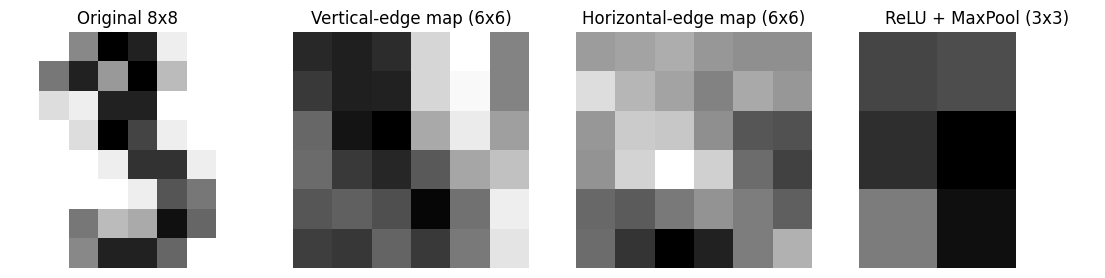

Image: (8, 8) -> conv: (6, 6) -> pool: (3, 3)
A 3x3 filter has only 9 weights, shared across the whole image.


In [5]:
digits = load_digits()
img = digits.images[3]                           # an 8x8 digit

def conv2d(image, kernel):
    kh, kw = kernel.shape
    H, W = image.shape
    out = np.zeros((H - kh + 1, W - kw + 1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            out[i, j] = np.sum(image[i:i+kh, j:j+kw] * kernel)
    return out

def max_pool(fmap, size=2):
    H, W = fmap.shape
    H2, W2 = H // size, W // size
    return fmap[:H2*size, :W2*size].reshape(H2, size, W2, size).max(axis=(1, 3))

vertical_edge   = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]])
horizontal_edge = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]])

fm_v = conv2d(img, vertical_edge)
fm_h = conv2d(img, horizontal_edge)
pooled = max_pool(relu(fm_v))

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, data, title in zip(axes,
        [img, fm_v, fm_h, pooled],
        ["Original 8x8", "Vertical-edge map (6x6)", "Horizontal-edge map (6x6)", "ReLU + MaxPool (3x3)"]):
    ax.imshow(data, cmap="gray_r"); ax.set_title(title); ax.axis("off")
plt.show()

print("Image:", img.shape, "-> conv:", fm_v.shape, "-> pool:", pooled.shape)
print("A 3x3 filter has only 9 weights, shared across the whole image.")

## 4. RNN: hidden state as memory

`h_t = tanh(W_x · x_t + W_h · h_(t-1) + b)`: the same weights are reused at every time step.

t=0  hidden state = [-0.898  0.418  0.547 -0.7  ]
t=1  hidden state = [ 0.986 -0.558  0.079  0.947]
t=2  hidden state = [-0.723 -0.101 -0.763 -0.086]
t=3  hidden state = [ 0.879 -0.43   0.151 -0.515]
t=4  hidden state = [ 0.715 -0.054 -0.47   0.651]
t=5  hidden state = [ 0.849 -0.382 -0.947  0.268]


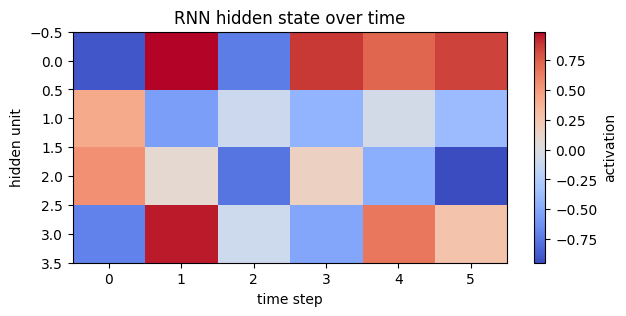

In [7]:
input_size, hidden_size, seq_len = 3, 4, 6
W_x = np.random.randn(hidden_size, input_size) * 0.5
W_h = np.random.randn(hidden_size, hidden_size) * 0.5
b   = np.zeros((hidden_size, 1))

sequence = [np.random.randn(input_size, 1) for _ in range(seq_len)]
h = np.zeros((hidden_size, 1))
history = []

for t, x_t in enumerate(sequence):
    h = np.tanh(W_x @ x_t + W_h @ h + b)
    history.append(h.ravel())
    print(f"t={t}  hidden state = {h.ravel().round(3)}")

history = np.array(history)
plt.figure(figsize=(7, 3))
plt.imshow(history.T, aspect="auto", cmap="coolwarm")
plt.colorbar(label="activation")
plt.xlabel("time step"); plt.ylabel("hidden unit"); plt.title("RNN hidden state over time")
plt.show()

## 5. Transformer: scaled dot-product self-attention

`Attention(Q, K, V) = softmax(Q·Kᵀ / sqrt(d_k)) · V`

Each token looks at every other token and decides how much to attend to it.

Attention weights (rows = query token):
[[0.63 0.   0.37 0.  ]
 [0.92 0.   0.07 0.  ]
 [0.93 0.   0.07 0.  ]
 [0.01 0.96 0.02 0.01]]
Row sums: [1. 1. 1. 1.]
Output shape: (4, 4)


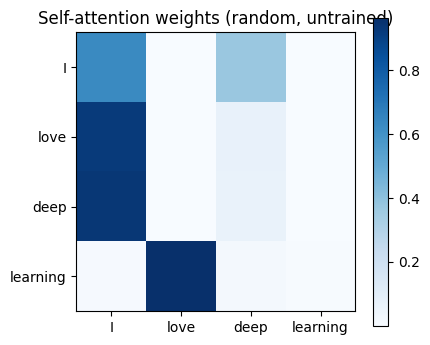

In [8]:
def softmax(z, axis=-1):
    e = np.exp(z - z.max(axis=axis, keepdims=True))
    return e / e.sum(axis=axis, keepdims=True)

tokens = ["I", "love", "deep", "learning"]
d_model, d_k = 8, 4
X = np.random.randn(len(tokens), d_model)         # token embeddings

W_q = np.random.randn(d_model, d_k)
W_k = np.random.randn(d_model, d_k)
W_v = np.random.randn(d_model, d_k)

Q, K, V = X @ W_q, X @ W_k, X @ W_v
scores  = Q @ K.T / np.sqrt(d_k)
weights = softmax(scores, axis=-1)                # each row sums to 1
output  = weights @ V

print("Attention weights (rows = query token):")
print(np.round(weights, 2))
print("Row sums:", weights.sum(axis=1))
print("Output shape:", output.shape)

plt.figure(figsize=(4.5, 4))
plt.imshow(weights, cmap="Blues")
plt.xticks(range(4), tokens); plt.yticks(range(4), tokens)
plt.title("Self-attention weights (random, untrained)"); plt.colorbar()
plt.show()

## 6. Autoencoder: compress, reconstruct, detect anomalies

The network learns to rebuild its input through a narrow bottleneck.
An input unlike the training data is reconstructed badly, which flags an anomaly.

Mean reconstruction error, normal digits (1-9): 0.0332
Mean reconstruction error, anomaly digit (0)  : 0.0549


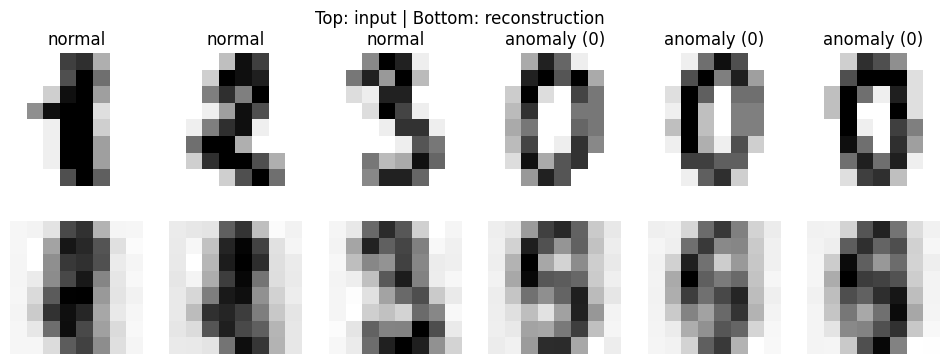

In [9]:
X = digits.data / 16.0                           # scale pixels to [0, 1]
normal_mask = digits.target != 0                 # train only on digits 1-9
X_normal = X[normal_mask]
X_zero   = X[~normal_mask]                       # digit 0 will be our "anomaly"

# 64 -> 32 -> 8 (bottleneck) -> 32 -> 64
autoencoder = MLPRegressor(hidden_layer_sizes=(32, 8, 32), activation="relu",
                           max_iter=800, random_state=42)
autoencoder.fit(X_normal, X_normal)

def recon_error(model, data):
    return ((model.predict(data) - data) ** 2).mean(axis=1)

err_normal = recon_error(autoencoder, X_normal)
err_zero   = recon_error(autoencoder, X_zero)
print(f"Mean reconstruction error, normal digits (1-9): {err_normal.mean():.4f}")
print(f"Mean reconstruction error, anomaly digit (0)  : {err_zero.mean():.4f}")

fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for k in range(3):
    orig = X_normal[k]
    axes[0, k].imshow(orig.reshape(8, 8), cmap="gray_r"); axes[0, k].set_title("normal"); axes[0, k].axis("off")
    axes[1, k].imshow(autoencoder.predict(orig[None])[0].reshape(8, 8), cmap="gray_r"); axes[1, k].axis("off")
for k in range(3):
    orig = X_zero[k]
    axes[0, k+3].imshow(orig.reshape(8, 8), cmap="gray_r"); axes[0, k+3].set_title("anomaly (0)"); axes[0, k+3].axis("off")
    axes[1, k+3].imshow(autoencoder.predict(orig[None])[0].reshape(8, 8), cmap="gray_r"); axes[1, k+3].axis("off")
axes[0, 0].set_ylabel("input"); axes[1, 0].set_ylabel("reconstruction")
plt.suptitle("Top: input | Bottom: reconstruction"); plt.show()

In [10]:
threshold = np.percentile(err_normal, 95)
detected = (err_zero > threshold).mean()
print(f"Threshold (95th percentile of normal error): {threshold:.4f}")
print(f"Fraction of zeros flagged as anomalies     : {detected:.2%}")

Threshold (95th percentile of normal error): 0.0573
Fraction of zeros flagged as anomalies     : 34.27%


**Observation:** the anomaly digit gets a clearly higher average reconstruction error, but this small autoencoder separates the classes only partly (in our run roughly a third of the zeros were flagged at this threshold). Real anomaly detectors use more training, tuning and better threshold selection. Try the practice exercises to improve it.

## 7. Architecture chooser by application

A small helper that maps the structure of the data to a suitable architecture.

In [11]:
guide = {
    "tabular":   ("MLP (or gradient boosting)",        "Fixed-size feature vectors"),
    "image":     ("CNN / Vision Transformer",          "Grid with local spatial patterns"),
    "sequence":  ("LSTM / GRU / Transformer",          "Ordered data, time dependence"),
    "text":      ("Transformer",                       "Tokens with long-range relations"),
    "graph":     ("Graph Neural Network",              "Nodes and edges"),
    "generate":  ("Diffusion / GAN / Transformer",     "Create new realistic samples"),
    "anomaly":   ("Autoencoder",                       "Learn normal, flag the unusual"),
}

applications = {
    "House price prediction": "tabular",
    "X-ray disease detection": "image",
    "Stock / sensor forecasting": "sequence",
    "Language translation": "text",
    "Drug molecule property prediction": "graph",
    "AI image creation": "generate",
    "Credit card fraud detection": "anomaly",
}

print(f"{'Application':36s} {'Suggested architecture':32s} Why")
print("-" * 100)
for app, kind in applications.items():
    arch, why = guide[kind]
    print(f"{app:36s} {arch:32s} {why}")

Application                          Suggested architecture           Why
----------------------------------------------------------------------------------------------------
House price prediction               MLP (or gradient boosting)       Fixed-size feature vectors
X-ray disease detection              CNN / Vision Transformer         Grid with local spatial patterns
Stock / sensor forecasting           LSTM / GRU / Transformer         Ordered data, time dependence
Language translation                 Transformer                      Tokens with long-range relations
Drug molecule property prediction    Graph Neural Network             Nodes and edges
AI image creation                    Diffusion / GAN / Transformer    Create new realistic samples
Credit card fraud detection          Autoencoder                      Learn normal, flag the unusual


## Summary

| Network | Core operation | Demo in this notebook |
|---|---|---|
| MLP | `f(Wx + b)` | Section 2 |
| CNN | Sliding filters + pooling | Section 3 |
| RNN | Hidden state across time | Section 4 |
| Transformer | Self-attention | Section 5 |
| Autoencoder | Reconstruct through a bottleneck | Section 6 |

## Practice exercises

1. Add a **diagonal-edge** kernel in the CNN section and visualize its feature map.
2. In the RNN section, increase `seq_len` to 30 and observe how the hidden state behaves.
3. Add a **mask** to the attention section so each token can only attend to earlier tokens (causal attention).
4. Change the autoencoder bottleneck from 8 to 2 neurons. How do reconstruction and anomaly detection change?
5. Add two new applications of your own to the architecture chooser.